                     Constant Mean - GARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -5184.90
Distribution:                  Normal   AIC:                           10377.8
Method:            Maximum Likelihood   BIC:                           10401.4
                                        No. Observations:                 2699
Date:                Tue, Sep 30 2025   Df Residuals:                     2698
Time:                        13:46:36   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1508  3.132e-02      4.814  1.476e-06 [8.939e-0

<Figure size 1200x600 with 0 Axes>

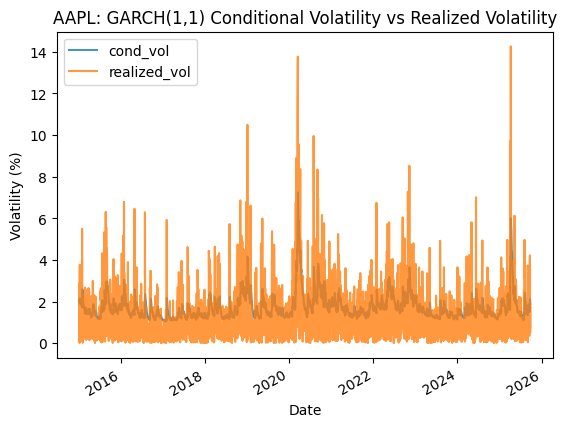

RMSE: 1.3205
MAE: 1.0280


<Figure size 1200x600 with 0 Axes>

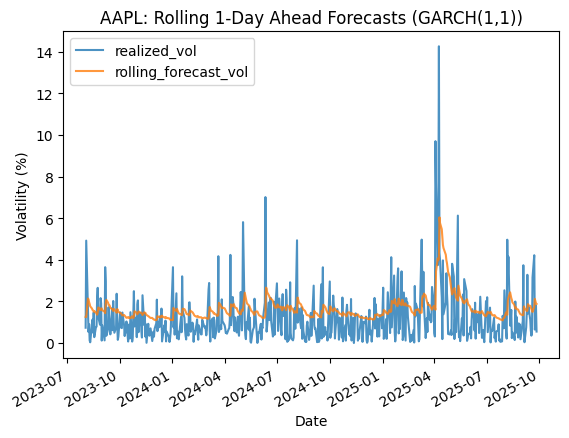

In [4]:
# 02_baseline_garch.ipynb

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from arch import arch_model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Data ---
df = pd.read_csv("../data/processed/AAPL_processed.csv", parse_dates=["Date"])
df.set_index("Date", inplace=True)

returns = df["log_return"] * 100  # scale to % for GARCH stability

# --- 2. Fit GARCH(1,1) Model ---
model = arch_model(returns, vol="Garch", p=1, q=1, dist="normal", mean="constant")
res = model.fit(disp="off")
print(res.summary())

# --- 3. Forecast Next-Day Volatility ---
forecast = res.forecast(horizon=1, reindex=False)

df["cond_var"] = res.conditional_volatility ** 2
df["cond_vol"] = res.conditional_volatility  # conditional volatility
df["realized_vol"] = np.sqrt(df["squared_return"]) * 100  # realized volatility proxy

# --- 4. Plot Conditional vs Realized Volatility ---
plt.figure(figsize=(12,6))
df[["cond_vol", "realized_vol"]].plot(alpha=0.8)
plt.title("AAPL: GARCH(1,1) Conditional Volatility vs Realized Volatility")
plt.ylabel("Volatility (%)")
plt.show()

# --- 5. Evaluation ---
valid_idx = df["realized_vol"].dropna().index
y_true = df.loc[valid_idx, "realized_vol"]
y_pred = df.loc[valid_idx, "cond_vol"]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

# --- 6. 1-Day Ahead Rolling Forecast (Walk-forward) ---
rolling_forecasts = []
train_size = int(len(returns) * 0.8)

for i in range(train_size, len(returns)):
    train = returns[:i]
    model = arch_model(train, vol="Garch", p=1, q=1)
    res = model.fit(disp="off")
    forecast = res.forecast(horizon=1)
    rolling_forecasts.append(forecast.variance.values[-1,0])

# Align forecasts with dates
forecast_series = pd.Series(rolling_forecasts, index=returns.index[train_size:])
df.loc[forecast_series.index, "rolling_forecast_vol"] = np.sqrt(forecast_series)

# --- 7. Plot Walk-forward Forecasts ---
plt.figure(figsize=(12,6))
df[["realized_vol", "rolling_forecast_vol"]].dropna().plot(alpha=0.8)
plt.title("AAPL: Rolling 1-Day Ahead Forecasts (GARCH(1,1))")
plt.ylabel("Volatility (%)")
plt.show()
